# Classical Music Meets Classical ML
**Alberto Gomez Soteres**, AIPI 520 Kaggle Competition

**Task:** predict which past patrons of the orchestra will buy a subscription (of any level) for the 2014-15 season. For each account in the test set we submit the probability that it buys a subscription, and the metric is the **AUROC**.

**Sections**
1. Setup
2. Loading the data
3. Data cleaning
4. What drives a subscription?
5. Feature engineering
6. Validation strategy
7. Baselines
8. Feature selection
9. Model tuning
10. Ensembles
11. First submission: logistic regression
12. One more feature: account age
13. Final model and submission
14. Conclusion

## 1. Setup

Here I import all the libraries used in the notebook and define the paths and the season we want to predict.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings('ignore')

# Folder with the competition csv files (in Colab, upload the csv files and use DATA_PATH = '')
DATA_PATH = '../data/'

# Folder where we save the submission files
SUBMISSIONS_PATH = '../submissions/'
os.makedirs(SUBMISSIONS_PATH, exist_ok=True)

# The season we want to predict is 2014-15, so all the history we use must be from 2013-14 or before
TARGET_YEAR = 2014

## 2. Loading the data

We have 9 files. `train.csv` and `test.csv` only have the account IDs (and the label for train), so all the information about each patron comes from the other files, joined by the account ID.

Two files need a small fix when we read them: `account.csv` has some special characters in the city names, so we read it with `latin-1`, and the concert files start with a hidden character, so we use `utf-8-sig`.

In [2]:
# First we read all the files
train = pd.read_csv(DATA_PATH + 'train.csv')
test = pd.read_csv(DATA_PATH + 'test.csv')
sample_submission = pd.read_csv(DATA_PATH + 'sample_submission.csv')
accounts = pd.read_csv(DATA_PATH + 'account.csv', encoding='latin-1')
subs = pd.read_csv(DATA_PATH + 'subscriptions.csv')
tickets = pd.read_csv(DATA_PATH + 'tickets_all.csv')
concerts = pd.read_csv(DATA_PATH + 'concerts.csv', encoding='utf-8-sig')
concerts_1415 = pd.read_csv(DATA_PATH + 'concerts_2014-15.csv', encoding='utf-8-sig')
zipcodes = pd.read_csv(DATA_PATH + 'zipcodes.csv')

# Then we print the size of each table
for name, df in [('train', train), ('test', test), ('accounts', accounts), ('subscriptions', subs),
                 ('tickets', tickets), ('concerts', concerts), ('concerts 2014-15', concerts_1415), ('zipcodes', zipcodes)]:
    print('{:<17} {}'.format(name, df.shape))

# Finally we look at the proportion of buyers in train
print('\nPositive rate in train: {:.3f}'.format(train['label'].mean()))

train             (6941, 2)
test              (2975, 1)
accounts          (19833, 10)
subscriptions     (28627, 9)
tickets           (2808, 8)
concerts          (103, 6)
concerts 2014-15  (6, 5)
zipcodes          (42522, 12)

Positive rate in train: 0.048


Only around 4.8% of the training accounts bought a subscription, so the classes are very imbalanced. This is why the competition uses AUROC and not accuracy: a model that predicts 0 for everyone would get ~95% accuracy and still be useless.

Before building anything, we check that the IDs connect correctly between the files and that train and test look similar.

In [3]:
sub_ids = set(subs['account.id'])
tix_ids = set(tickets['account.id'])

# First we check that every train and test account appears in the accounts file
print('Train accounts found in account.csv:', train['account.id'].isin(accounts['account.id']).mean())
print('Test accounts found in account.csv:', test['ID'].isin(accounts['account.id']).mean())
print('Overlap between train and test:', len(set(train['account.id']) & set(test['ID'])))

# Then we compare how many accounts have some purchase history in each set
for name, ids in [('train', train['account.id']), ('test', test['ID'])]:
    print('{:<6} with subscriptions: {:.3f} | with tickets: {:.3f}'.format(name, ids.isin(sub_ids).mean(), ids.isin(tix_ids).mean()))

# Finally we check that the history files do not have any 2014-15 data, which would be leakage
print('\nLast subscription season:', subs['season'].max())
print('Last ticket season:', tickets['season'].max())

Train accounts found in account.csv: 1.0
Test accounts found in account.csv: 1.0
Overlap between train and test: 0
train  with subscriptions: 0.318 | with tickets: 0.105
test   with subscriptions: 0.317 | with tickets: 0.098

Last subscription season: 2013-2014
Last ticket season: 2013-2014


Every account is in `account.csv`, train and test do not overlap, and both sets have almost the same share of accounts with subscription and ticket history. The history files stop at 2013-14, so there is no data from the season we want to predict.

## 3. Data cleaning

While exploring the files I found a few problems that we need to fix before building the features:

- **Subscription `price.level`**: the meaning is not clear at first. Comparing it with the `section` column (below) shows it is a price scale: 1 = most expensive sections (Premium Orchestra, Box), 2 = Orchestra, 3 = Balcony Front and 4 = Balcony Rear or Gallery (cheapest). Level 0 only appears in a few seasons, and the price level is missing for 2002-2005.
- **Ticket `price.level`**: it mixes numbers with text (`4.0`, `Adult`, `GA`, `Youth`). We convert it to numbers, so the text values become missing.
- **`first.donated`**: every first donation between 1985 and 1992 is on July 4th, so these dates are placeholders from an old system.
- **Zip codes**: some have 9 digits (`94025-2706`), some lost the first zero (`8540` instead of `08540`) and some are from other countries. In `zipcodes.csv` the zip is stored as a number, so we add the zeros back to be able to join the tables.

In [4]:
# We compare the subscription price levels with the seat sections to understand their order
recent = subs[subs['season'] >= '2005-2006']
pd.crosstab(recent['section'].fillna('missing'), recent['price.level'].fillna(-1))

price.level,-1.0,0.0,1.0,2.0,3.0,4.0
section,,,,,,
Balcony,0,0,0,1,0,194
Balcony Front,0,0,0,265,859,67
Balcony Rear,0,0,0,0,0,382
Box,0,0,110,0,0,0
Boxes House Left,0,0,11,0,0,0
Boxes House Right,0,0,13,0,0,0
Dress Circle,0,0,0,82,269,11
Floor,0,0,1,0,0,0
Gallery,0,0,0,0,0,47


In [5]:
# First we create a numeric year for each season (2013-2014 -> 2013)
subs['year'] = subs['season'].str[:4].astype(int)
tickets['year'] = tickets['season'].str[:4].astype(int)

# Full subscriptions include all the concerts of the season, the other packages only a part of them
subs['is_full'] = (subs['package'] == 'Full').astype(int)

# Then we convert the ticket price levels to numbers, so text values like 'Adult' or 'GA' become NaN
tickets['price.level'] = pd.to_numeric(tickets['price.level'], errors='coerce')

# We also convert the donation dates to datetime
accounts['first.donated'] = pd.to_datetime(accounts['first.donated'])

# Now we clean the zip codes. We use the billing zip (or the shipping zip if billing is missing) and keep 5 characters
zip5 = accounts['billing.zip.code'].fillna(accounts['shipping.zip.code']).astype(str).str.strip().str[:5]

# Then we add back the first zero when it was lost, and anything that is not 5 digits (foreign codes) becomes NaN
zip5 = zip5.where(~zip5.str.fullmatch(r'\d{4}'), '0' + zip5)
accounts['zip5'] = zip5.where(zip5.str.fullmatch(r'\d{5}'))

# Finally we prepare the zipcodes table so we can join it with the accounts
zipcodes['zip5'] = zipcodes['Zipcode'].astype(str).str.zfill(5)
zipcodes['avg_income'] = zipcodes['TotalWages'] / zipcodes['TaxReturnsFiled']

print('Accounts with a valid zip that matches zipcodes.csv: {:.3f}'.format(accounts['zip5'].isin(zipcodes['zip5']).mean()))

Accounts with a valid zip that matches zipcodes.csv: 0.848


## 4. What drives a subscription?

Before choosing the features, I want to see how the label relates to the subscription history. The simplest idea is that patrons who were subscribed last season are very likely to renew.

In [6]:
# First we mark which training accounts were subscribed in 2013-14 and which ones ever had a subscription
tr = train.copy()
subs_2013 = set(subs.loc[subs['year'] == TARGET_YEAR - 1, 'account.id'])
tr['subscribed_2013'] = tr['account.id'].isin(subs_2013)
tr['any_subscription'] = tr['account.id'].isin(sub_ids)

# Then we look at the proportion of buyers in each group
tr.groupby(['any_subscription', 'subscribed_2013'])['label'].agg(['mean', 'count'])

mean  count
any_subscription subscribed_2013                 
False            False            0.006757   4736
True             False            0.009677   1860
                 True             0.817391    345

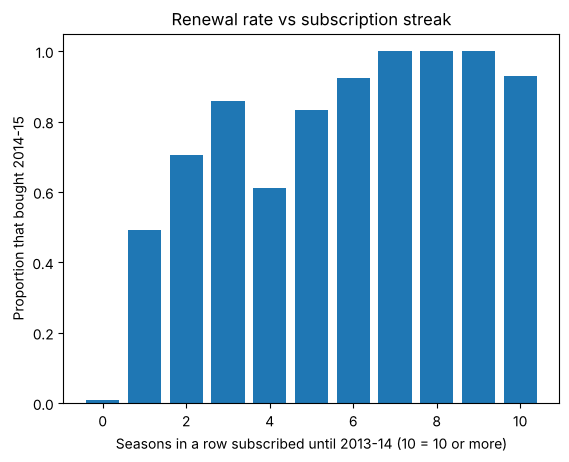

In [7]:
def streak_until(years, last_year):
    '''
    Counts how many seasons in a row an account was subscribed, going backwards from last_year

    Inputs:
        years(iterable): seasons (start year) in which the account had a subscription
        last_year(int): season where we start counting backwards

    Returns:
        streak(int): number of seasons in a row subscribed up to last_year
    '''
    years = set(years)
    streak = 0

    # We keep going back one season while the account was still subscribed
    while (last_year - streak) in years:
        streak += 1
    return streak


# First we compute the streak of each account until 2013-14 (we group 10 or more seasons together)
streaks = subs.groupby('account.id')['year'].apply(lambda y: streak_until(y, TARGET_YEAR - 1))
tr['streak'] = tr['account.id'].map(streaks).fillna(0).clip(upper=10)

# Then we plot the renewal rate for each streak length
renewal = tr.groupby('streak')['label'].mean()

plt.bar(renewal.index, renewal.values)
plt.xlabel('Seasons in a row subscribed until 2013-14 (10 = 10 or more)')
plt.ylabel('Proportion that bought 2014-15')
plt.title('Renewal rate vs subscription streak')
plt.show()

The subscription history is clearly the strongest signal. Patrons subscribed in 2013-14 renew around 82% of the time, while accounts that never subscribed buy less than 1% of the time. The renewal rate also goes up with the number of seasons in a row, so loyalty matters, not only the last season.

However, there are 50 buyers that were not subscribed in 2013-14 (32 of them never subscribed at all). These are the hard cases, and for them the tickets and donations should help.

## 5. Feature engineering

Here I build all the features with one function, `build_features()`, that takes a list of account IDs. Since I use the same function for the train and test IDs, both sets always get the same columns, calculated in the same way.

The features are in 4 groups:

| Group | Source | Idea |
|---|---|---|
| Subscriptions | subscriptions.csv | loyalty, recency and size of the past subscriptions |
| Tickets | tickets_all.csv | single-ticket buyers who may become subscribers |
| Donations | account.csv | patrons who support the orchestra beyond buying tickets |
| Location | account.csv + zipcodes.csv | distance to the concerts and income of the zip code |

If an account has no history, its counts are 0 and its "years since" features are 30 (longer than any real gap). Money amounts have very long tails, so we use `log1p`.

In [8]:
def subscription_features(subs):
    '''
    Creates one row of subscription history features per account

    Inputs:
        subs(pd.DataFrame): cleaned subscriptions table

    Returns:
        feats(pd.DataFrame): subscription features indexed by account id
    '''
    g = subs.groupby('account.id')

    # First we compute the general history features (loyalty and size of the subscriptions)
    feats = pd.DataFrame({
        'sub_n_seasons': g['year'].nunique(),
        'sub_first_year': g['year'].min(),
        'sub_last_year': g['year'].max(),
        'sub_total_tier': g['subscription_tier'].sum(),
        'sub_mean_seats': g['no.seats'].mean(),
        'sub_n_locations': g['location'].nunique(),
        'sub_full_share': g['is_full'].mean(),
        'sub_multiple_any': g['multiple.subs'].apply(lambda s: (s == 'yes').any()).astype(int),
        'sub_streak': g['year'].apply(lambda y: streak_until(y, TARGET_YEAR - 1)),
        'sub_n_last5': g['year'].apply(lambda y: (y >= TARGET_YEAR - 5).sum()),
    })

    # Then we add a flag for each of the last 3 seasons
    for k in [1, 2, 3]:
        season = TARGET_YEAR - k
        feats['sub_{}'.format(season)] = g['year'].apply(lambda y: int(season in set(y)))

    # Finally we describe the most recent subscription of each account
    last = subs.sort_values('year').groupby('account.id').tail(1).set_index('account.id')
    feats['sub_last_seats'] = last['no.seats']
    feats['sub_last_tier'] = last['subscription_tier']
    feats['sub_last_full'] = last['is_full']
    feats['sub_last_price_level'] = last['price.level']

    return feats


def ticket_features(tickets):
    '''
    Creates one row of ticket history features per account

    Inputs:
        tickets(pd.DataFrame): cleaned tickets table

    Returns:
        feats(pd.DataFrame): ticket features indexed by account id
    '''
    g = tickets.groupby('account.id')

    # We count the tickets and seasons, and check if the account went to a family concert
    feats = pd.DataFrame({
        'tix_n': g.size(),
        'tix_n_seasons': g['year'].nunique(),
        'tix_last_year': g['year'].max(),
        'tix_total_seats': g['no.seats'].sum(),
        'tix_mean_price_level': g['price.level'].mean(),
        'tix_family': g['location'].apply(lambda s: (s == 'Family concert').any()).astype(int),
    })

    # We also add a flag for the accounts that bought tickets in 2013-14
    feats['tix_{}'.format(TARGET_YEAR - 1)] = g['year'].apply(lambda y: int((TARGET_YEAR - 1) in set(y)))

    return feats

In [9]:
def build_features(ids):
    '''
    Builds the full feature matrix for a list of accounts. The same function is used for train and test

    Inputs:
        ids(pd.Series): account ids

    Returns:
        X(pd.DataFrame): feature matrix with one row per account, in the same order as ids
    '''
    X = pd.DataFrame(index=pd.Index(ids, name='account.id'))

    # First we join the subscription and ticket history. Accounts without history get NaN here
    X = X.join(subscription_features(subs)).join(ticket_features(tickets))
    X['has_sub'] = X['sub_n_seasons'].notna().astype(int)
    X['has_tix'] = X['tix_n'].notna().astype(int)

    # Then we turn the years into recency and tenure, using 30 years when there is no history
    X['years_since_sub'] = (TARGET_YEAR - X['sub_last_year']).fillna(30)
    X['sub_tenure'] = (TARGET_YEAR - X['sub_first_year']).fillna(0)
    X['years_since_tix'] = (TARGET_YEAR - X['tix_last_year']).fillna(30)
    X = X.drop(columns=['sub_last_year', 'sub_first_year', 'tix_last_year'])

    # For the counts no history means 0. For the price levels we use a middle value (2.5)
    count_cols = [c for c in X.columns if c.startswith(('sub_', 'tix_')) and 'price_level' not in c]
    X[count_cols] = X[count_cols].fillna(0)
    X['sub_last_price_level'] = X['sub_last_price_level'].fillna(2.5)
    X['tix_mean_price_level'] = X['tix_mean_price_level'].fillna(2.5)

    # Now we add the donation features. Amounts have very long tails so we use log1p
    acc = accounts.set_index('account.id').loc[ids]
    X['don_2013'] = np.log1p(acc['amount.donated.2013'].values)
    X['don_lifetime'] = np.log1p(acc['amount.donated.lifetime'].values)
    X['don_n'] = acc['no.donations.lifetime'].values
    first_year = acc['first.donated'].dt.year
    X['years_since_first_don'] = (TARGET_YEAR - first_year).fillna(0).values
    X['first_don_2014'] = (first_year == TARGET_YEAR).astype(int).values
    X['has_relationship'] = acc['relationship'].notna().astype(int).values
    X['has_billing_zip'] = acc['billing.zip.code'].notna().astype(int).values

    # After this we add the location features by joining the zip code table
    z = acc[['zip5']].merge(zipcodes[['zip5', 'State', 'Lat', 'Long', 'EstimatedPopulation', 'avg_income']],
                            on='zip5', how='left')
    X['in_CA'] = (z['State'] == 'CA').astype(int).values

    # Distance to San Francisco with the haversine formula. Unknown locations get a far distance (5000 km)
    lat1, lon1 = np.radians(37.7749), np.radians(-122.4194)
    lat2, lon2 = np.radians(z['Lat'].values), np.radians(z['Long'].values)
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    dist = 2 * 6371 * np.arcsin(np.sqrt(a))
    X['dist_sf_km'] = np.log1p(np.nan_to_num(dist, nan=5000))

    # Finally, the population and income of the zip code. Missing values are filled with the median
    X['zip_log_pop'] = np.log1p(z['EstimatedPopulation'].values)
    X['zip_log_income'] = np.log1p(z['avg_income'].values)
    X['zip_log_pop'] = X['zip_log_pop'].fillna(X['zip_log_pop'].median())
    X['zip_log_income'] = X['zip_log_income'].fillna(X['zip_log_income'].median())

    return X

In [10]:
# We build the features for train and test with the same function
X = build_features(train['account.id'])
y = train['label'].values
X_test = build_features(test['ID'])

# Then we check that both matrices have the same columns and no missing values
print('Train features:', X.shape, '| Test features:', X_test.shape)
print('Missing values -> train: {}, test: {}'.format(X.isna().sum().sum(), X_test.isna().sum().sum()))
print('Same columns in train and test:', list(X.columns) == list(X_test.columns))
X.head()

Train features: (6941, 37) | Test features: (2975, 37)
Missing values -> train: 0, test: 0
Same columns in train and test: True


,sub_n_seasons,sub_total_tier,sub_mean_seats,sub_n_locations,sub_full_share,sub_multiple_any,sub_streak,sub_n_last5,sub_2013,sub_2012,...,don_lifetime,don_n,years_since_first_don,first_don_2014,has_relationship,has_billing_zip,in_CA,dist_sf_km,zip_log_pop,zip_log_income
account.id,,,,,,,,,,,,,,,,,,,,,
001i000000NuRo3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0,0.0,0,0,0,0,8.517393,10.023889,11.116923
001i000000NuRxd,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0,0.0,0,0,0,0,8.517393,10.023889,11.116923
001i000000NuQGN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0,0.0,0,0,1,1,3.559948,9.739674,11.023493
001i000000NuPfL,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0,0.0,0,0,1,1,2.449688,8.377011,11.233593
001i000000NuQkP,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0,0.0,0,0,1,1,2.847226,10.092578,11.010893


Both matrices have the same 37 columns and no missing values. We also save the feature groups in a dictionary, because later we use it to check how much each group helps.

In [11]:
# We save the columns of each group, so we can remove one group at a time later
feature_groups = {
    'subscriptions': [c for c in X.columns if c.startswith('sub_')] + ['has_sub', 'years_since_sub'],
    'tickets': [c for c in X.columns if c.startswith('tix_')] + ['has_tix', 'years_since_tix'],
    'donations': [c for c in X.columns if c.startswith('don_')] + ['years_since_first_don', 'first_don_2014', 'has_relationship'],
    'location': ['has_billing_zip', 'in_CA', 'dist_sf_km', 'zip_log_pop', 'zip_log_income'],
}

for group, cols in feature_groups.items():
    print('{:<14} {} features'.format(group, len(cols)))

subscriptions  18 features
tickets        8 features
donations      6 features
location       5 features


## 6. Validation strategy

We need a reliable way to compare models before submitting to Kaggle. The public leaderboard only uses part of the test set and the final result depends on the private part, so choosing models with the public score could make us overfit to it.

I use **stratified 5-fold cross-validation, repeated 3 times with different shuffles** (15 AUROC values per model):

- **Cross-validation instead of one validation set**: we only have 332 buyers. A single 20% validation set would have ~66 of them, so the AUROC would change a lot depending on which accounts fall in it.
- **Stratified**: every fold keeps the same ~4.8% of buyers as the full training set.
- **Repeated**: averaging 3 different shuffles makes the result more stable, and the standard deviation tells us if a difference between two models is real or just noise.

The function always uses `random_state=0`, so every model is evaluated on exactly the same 15 splits. This way I can also compare two models fold by fold.

In [12]:
def cv_auroc(model, X, y, n_splits=5, n_repeats=3, random_state=0):
    '''
    Evaluates a model using repeated stratified K-fold cross-validation and AUROC

    Inputs:
        model(sklearn.base.BaseEstimator): instantiated scikit-learn model or pipeline
        X(pd.DataFrame): feature matrix
        y(np.ndarray): labels
        n_splits(int): number of folds
        n_repeats(int): number of times the K-fold is repeated with a different shuffle
        random_state(int): random seed for the splits

    Returns:
        aucs(np.ndarray): validation AUROC of each fold (n_splits * n_repeats values)
    '''
    # First we create the folds. Stratified keeps the same proportion of buyers in every fold
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)

    aucs = []
    for train_index, val_index in cv.split(X, y):
        X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
        y_train_fold, y_val_fold = y[train_index], y[val_index]

        # Then we fit the model on the training folds and get the probabilities for the validation fold
        model.fit(X_train_fold, y_train_fold)
        val_probs = model.predict_proba(X_val_fold)[:, 1]

        # Finally we calculate the AUROC of this fold
        aucs.append(roc_auc_score(y_val_fold, val_probs))

    return np.array(aucs)

## 7. Baselines

Before tuning anything, I want to know which score a model has to beat. Giving the same probability to every account gets an AUROC of 0.5, but that is too easy to beat here. A better reference is a simple rule based on what we saw in section 4: rank the patrons by how loyal they are, without any model.

Then I train two models from class with simple settings, to have a first ML score and check that the whole pipeline works.

In [13]:
# These rules give a score to each account without training anything. A higher score means more likely to buy
rules = {
    'Subscribed in 2013-14': X['sub_2013'],
    'Seasons in a row': X['sub_streak'],
    'Seasons in a row, then most recent': X['sub_streak'] + 1 / (1 + X['years_since_sub']),
}

# We score each rule on the same 15 validation folds that we use for the models
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
for name, score in rules.items():
    aucs = np.array([roc_auc_score(y[val_index], score.values[val_index]) for _, val_index in cv.split(X, y)])
    print('{:<36} CV AUROC = {:.4f} (+/- {:.4f})'.format(name, aucs.mean(), aucs.std()))

Subscribed in 2013-14                CV AUROC = 0.9199 (+/- 0.0243)
Seasons in a row                     CV AUROC = 0.9221 (+/- 0.0244)
Seasons in a row, then most recent   CV AUROC = 0.9351 (+/- 0.0191)


Ranking the patrons only by "subscribed in 2013-14" already gives 0.920, and the best rule (seasons in a row, and among the rest the most recent subscribers first) reaches **0.935**. So a model has to be clearly above 0.935 to be worth it.

In [14]:
# We define the two baseline models
lr_baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
rf_baseline = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0)

# Then we evaluate both of them with the same CV
for name, model in [('Logistic Regression', lr_baseline), ('Random Forest', rf_baseline)]:
    aucs = cv_auroc(model, X, y)
    print('{:<20} CV AUROC = {:.4f} (+/- {:.4f})'.format(name, aucs.mean(), aucs.std()))

Logistic Regression  CV AUROC = 0.9773 (+/- 0.0073)


Random Forest        CV AUROC = 0.9723 (+/- 0.0112)


Both models are already above 0.97, so they are clearly better than the best simple rule (0.935). The logistic regression is a bit better than the random forest. This makes sense, because the strongest features (subscribed last season, streak, number of seasons) always push the probability in the same direction, and a linear model captures that well.

## 8. Feature selection

Here I check which features really help, with two methods from class:

1. **Removing one group at a time**: we run the same CV without each group and see how much the AUROC drops. If removing a group does not hurt, the group is not adding information.
2. **Random forest feature importance**: how much each feature reduces the Gini impurity on average across all the trees.

In [15]:
lr_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
rf_model = RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0)

ablation = []

# First we evaluate both models with all the features as a reference
ablation.append({'features': 'All features', 'n_features': X.shape[1],
                 'LR AUROC': cv_auroc(lr_model, X, y).mean(), 'RF AUROC': cv_auroc(rf_model, X, y).mean()})

# Then we remove one group at a time and repeat the CV
for group, cols in feature_groups.items():
    X_reduced = X.drop(columns=cols)
    ablation.append({'features': 'Without ' + group, 'n_features': X_reduced.shape[1],
                     'LR AUROC': cv_auroc(lr_model, X_reduced, y).mean(), 'RF AUROC': cv_auroc(rf_model, X_reduced, y).mean()})

# Finally we also check each group on its own
for group, cols in feature_groups.items():
    ablation.append({'features': 'Only ' + group, 'n_features': len(cols),
                     'LR AUROC': cv_auroc(lr_model, X[cols], y).mean(), 'RF AUROC': cv_auroc(rf_model, X[cols], y).mean()})

ablation = pd.DataFrame(ablation).round(4)
ablation

,features,n_features,LR AUROC,RF AUROC
0,All features,37,0.9773,0.9723
1,Without subscriptions,19,0.9121,0.9135
2,Without tickets,29,0.9736,0.9696
3,Without donations,31,0.9720,0.9676
4,Without location,32,0.9733,0.9706
5,Only subscriptions,18,0.9567,0.9585
6,Only tickets,8,0.5233,0.5050
7,Only donations,6,0.8788,0.8837
8,Only location,5,0.6555,0.6837


As we can see, every group helps, because removing any of them lowers the AUROC for both models:

- **Subscriptions** are by far the most important group. Without them the AUROC falls from ~0.977 to ~0.91, and on their own they already reach ~0.957.
- **Donations** are the second most useful group. On their own they reach ~0.88, which makes sense because donors care about the orchestra.
- **Tickets** and **location** are weak on their own (~0.52 and ~0.66), but they still add a bit on top of the other groups.

So I keep the 4 groups. Next we look at the importance of each feature.

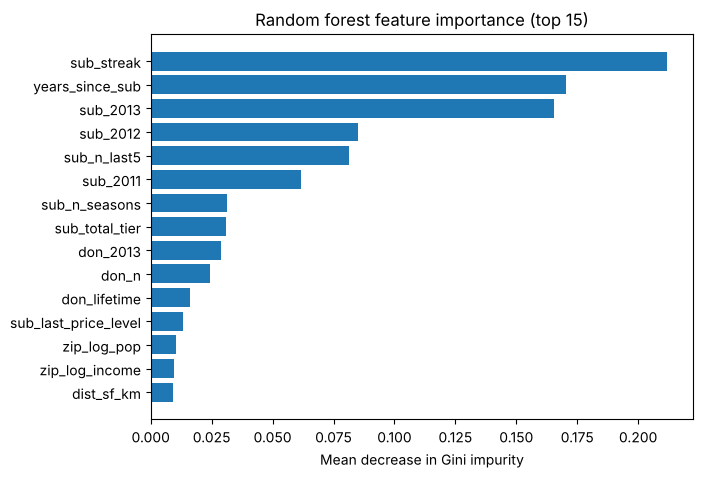

Features with importance < 0.001: ['sub_last_full', 'has_sub', 'has_tix', 'tix_2013', 'in_CA', 'sub_multiple_any', 'tix_family', 'has_billing_zip', 'has_relationship']


In [16]:
# First we fit the random forest on all the training data and take the feature importances
rf_model.fit(X, y)
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

# Then we plot the 15 most important features
top = importances.head(15)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values)
plt.xlabel('Mean decrease in Gini impurity')
plt.title('Random forest feature importance (top 15)')
plt.show()

# Finally we list the features that the forest almost never uses
print('Features with importance < 0.001:', list(importances[importances < 0.001].index))

The ranking agrees with the previous table. The top features are all about loyalty and recency: the streak, the years since the last subscription and being subscribed in 2013-14. Donations come right after.

Some yes/no features have almost zero importance. Most of them are very rare (for example `tix_family` or `has_relationship`), so the forest almost never splits on them. Before removing them, we check with the CV if dropping them helps the logistic regression.

In [17]:
low_importance = list(importances[importances < 0.001].index)

# We compare the logistic regression with and without the low importance features
aucs_all = cv_auroc(lr_model, X, y)
aucs_reduced = cv_auroc(lr_model, X.drop(columns=low_importance), y)

print('All {} features:     CV AUROC = {:.4f}'.format(X.shape[1], aucs_all.mean()))
print('Without {} features: CV AUROC = {:.4f}'.format(len(low_importance), aucs_reduced.mean()))

All 37 features:     CV AUROC = 0.9773
Without 9 features: CV AUROC = 0.9766


Removing them does not help (it is slightly worse), so I decided to **keep all 37 features**. With 6,941 accounts, 37 features is not too many, and the logistic regression already uses L2 regularization, which makes the coefficients of the useless features small.

## 9. Model tuning

Here I compare the models from class, and for each one I tune its main hyperparameters with the same CV:

| Model | Hyperparameters | Notes |
|---|---|---|
| Logistic regression | `C` (inverse of the regularization strength), `class_weight` | standardized features |
| Random forest | `min_samples_leaf`, `max_features` | no scaling needed |
| KNN | `n_neighbors` | based on distances, so standardized features |
| SVC (RBF kernel) | `C` | it does not give probabilities, so we use **Platt scaling** (`CalibratedClassifierCV` with `method='sigmoid'`) |
| AdaBoost and gradient boosting | `n_estimators`, `learning_rate`, `max_depth` | no scaling needed |
| Neural network (MLP) | `hidden_layer_sizes`, `alpha` (L2 penalty) | standardized features |

### 9.1 Logistic regression

C = 0.001  CV AUROC = 0.9612 (+/- 0.0139)


C = 0.01   CV AUROC = 0.9698 (+/- 0.0110)


C = 0.1    CV AUROC = 0.9770 (+/- 0.0077)


C = 1      CV AUROC = 0.9773 (+/- 0.0073)


C = 10     CV AUROC = 0.9773 (+/- 0.0074)


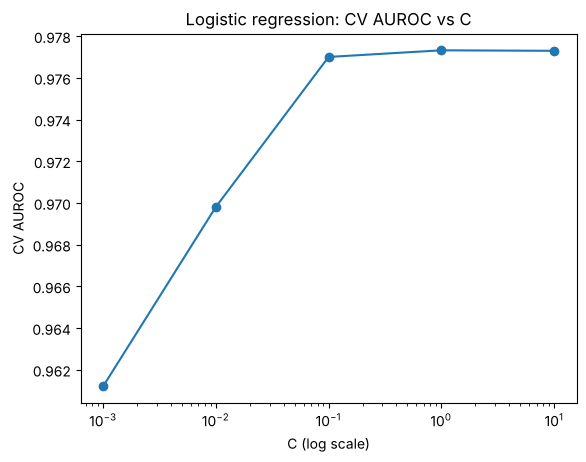

In [18]:
C_values = [0.001, 0.01, 0.1, 1, 10]
lr_results = []

# For each value of C we run the CV and save the mean AUROC
for C in C_values:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    aucs = cv_auroc(model, X, y)
    lr_results.append(aucs.mean())
    print('C = {:<6} CV AUROC = {:.4f} (+/- {:.4f})'.format(C, aucs.mean(), aucs.std()))

# Then we plot the AUROC against C (log scale)
plt.plot(C_values, lr_results, marker='o')
plt.xscale('log')
plt.xlabel('C (log scale)')
plt.ylabel('CV AUROC')
plt.title('Logistic regression: CV AUROC vs C')
plt.show()

Small values of `C` mean strong regularization, and the model underfits (0.961 with `C=0.001`). The AUROC goes up until `C=0.1` and then stays flat around 0.977. Since `C=1` and `C=10` give the same result, I keep `C=1` (the default), which still has some regularization.

Since only 4.8% of the accounts are buyers, I also check if giving more weight to the buyers during training helps. This has a similar effect to oversampling the buyers.

In [19]:
# class_weight='balanced' gives each class a weight inversely proportional to its size
lr_balanced = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000, class_weight='balanced'))
lr_default = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000))

# We compare both versions on the same folds
aucs_balanced = cv_auroc(lr_balanced, X, y)
aucs_default = cv_auroc(lr_default, X, y)
print('Default weights:  CV AUROC = {:.4f} (+/- {:.4f})'.format(aucs_default.mean(), aucs_default.std()))
print('Balanced weights: CV AUROC = {:.4f} (+/- {:.4f})'.format(aucs_balanced.mean(), aucs_balanced.std()))
print('Balanced is better in {}/15 folds'.format(np.sum(aucs_balanced > aucs_default)))

Default weights:  CV AUROC = 0.9773 (+/- 0.0073)
Balanced weights: CV AUROC = 0.9769 (+/- 0.0079)
Balanced is better in 7/15 folds


The balanced weights give almost the same AUROC (0.9769 vs 0.9773) and they are only better in 7 of the 15 folds. This makes sense, because the AUROC only depends on the order of the probabilities, and changing the weights of the classes moves the probabilities but barely changes their order. So I keep the default weights and I do not resample the data.

### 9.2 Random forest

In [20]:
rf_results = []

# We try every combination of min_samples_leaf and max_features
for msl in [1, 5, 10, 20, 40]:
    for mf in ['sqrt', 0.5]:
        model = RandomForestClassifier(n_estimators=300, min_samples_leaf=msl, max_features=mf, n_jobs=-1, random_state=0)
        aucs = cv_auroc(model, X, y)
        rf_results.append({'min_samples_leaf': msl, 'max_features': mf, 'CV AUROC': aucs.mean(), 'std': aucs.std()})

# Then we show the results as a table
rf_results = pd.DataFrame(rf_results).round(4)
rf_results.pivot(index='min_samples_leaf', columns='max_features', values='CV AUROC')

max_features,0.5,sqrt
min_samples_leaf,,
1,0.9534,0.9584
5,0.9662,0.9725
10,0.9692,0.9734
20,0.9686,0.9727
40,0.9678,0.9709


This is the bias-variance tradeoff from class. With `min_samples_leaf=1` the trees are very deep and the model overfits (~0.958), while with very large leaves it starts to underfit. The best result is `min_samples_leaf=10` with `max_features='sqrt'`. Using `'sqrt'` is better than 0.5 because the trees are more different from each other, which lowers the variance of the forest.

### 9.3 KNN

n_neighbors = 25   CV AUROC = 0.9479 (+/- 0.0178)


n_neighbors = 50   CV AUROC = 0.9547 (+/- 0.0170)


n_neighbors = 100  CV AUROC = 0.9601 (+/- 0.0163)


n_neighbors = 200  CV AUROC = 0.9663 (+/- 0.0138)


n_neighbors = 500  CV AUROC = 0.9729 (+/- 0.0089)


n_neighbors = 800  CV AUROC = 0.9732 (+/- 0.0098)


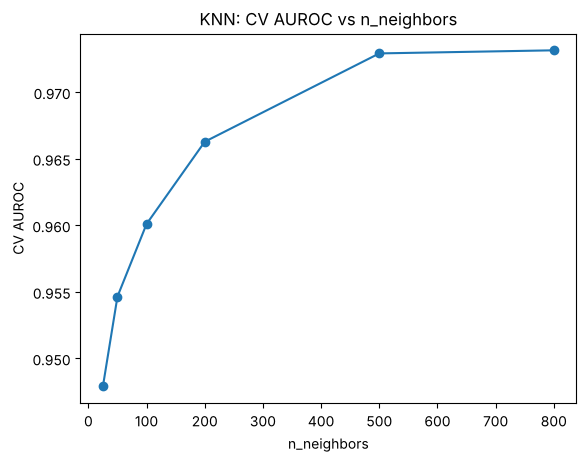

In [21]:
k_values = [25, 50, 100, 200, 500, 800]
knn_results = []

# For each number of neighbors we run the CV and save the mean AUROC
for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    aucs = cv_auroc(model, X, y)
    knn_results.append(aucs.mean())
    print('n_neighbors = {:<4} CV AUROC = {:.4f} (+/- {:.4f})'.format(k, aucs.mean(), aucs.std()))

# Then we plot the AUROC against the number of neighbors
plt.plot(k_values, knn_results, marker='o')
plt.xlabel('n_neighbors')
plt.ylabel('CV AUROC')
plt.title('KNN: CV AUROC vs n_neighbors')
plt.show()

KNN needs a very large number of neighbors here. With only 4.8% buyers, a small group of neighbors has very few buyers, so the probabilities are very rough (with `n_neighbors=25` the probability can only take 26 different values). With 500-800 neighbors the probabilities are smoother and the AUROC reaches ~0.973, but it is still below the logistic regression.

### 9.4 SVC with Platt scaling

In [22]:
svc_results = []

for C in [0.01, 0.03, 0.1, 1]:
    # Platt scaling fits a sigmoid on the SVC output to turn it into probabilities
    model = make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(C=C, kernel='rbf'), method='sigmoid', cv=3))
    aucs = cv_auroc(model, X, y)
    svc_results.append(aucs.mean())
    print('C = {:<5} CV AUROC = {:.4f} (+/- {:.4f})'.format(C, aucs.mean(), aucs.std()))

C = 0.01  CV AUROC = 0.9551 (+/- 0.0170)


C = 0.03  CV AUROC = 0.9554 (+/- 0.0166)


C = 0.1   CV AUROC = 0.9533 (+/- 0.0173)


C = 1     CV AUROC = 0.9490 (+/- 0.0192)


The SVC is the weakest model so far (~0.955 at best) and it gets worse when `C` increases. SVCs work best with few rows and many features, and here we have the opposite, plus a strong class imbalance. Also, its probabilities are added afterwards with Platt scaling, they are not part of the model.

### 9.5 Boosting

Random forests train many trees independently and average them (bagging). Boosting is the other ensemble of trees we saw in class: each new tree focuses on the mistakes of the previous ones. I try the two versions from class, AdaBoost (with decision stumps) and gradient boosting.

In [23]:
ada_results = []

# For AdaBoost we tune the number of weak learners and the learning rate
for n in [50, 100, 200, 400]:
    for lr in [0.1, 0.5, 1.0]:
        model = AdaBoostClassifier(n_estimators=n, learning_rate=lr, random_state=0)
        aucs = cv_auroc(model, X, y)
        ada_results.append({'n_estimators': n, 'learning_rate': lr, 'CV AUROC': aucs.mean()})

# Then we show the results as a table
ada_results = pd.DataFrame(ada_results).round(4)
ada_results.pivot(index='n_estimators', columns='learning_rate', values='CV AUROC')

learning_rate,0.1,0.5,1.0
n_estimators,,,
50,0.9618,0.9742,0.9709
100,0.9616,0.9748,0.9734
200,0.9710,0.9755,0.9736
400,0.9762,0.9751,0.9731


In [24]:
gb_results = []

# For gradient boosting we keep the trees small and use subsampling, two of the ways from class to reduce overfitting
for lr in [0.05, 0.1]:
    for depth in [2, 3]:
        model = GradientBoostingClassifier(n_estimators=200, learning_rate=lr, max_depth=depth, subsample=0.8, random_state=0)
        aucs = cv_auroc(model, X, y)
        gb_results.append({'learning_rate': lr, 'max_depth': depth, 'CV AUROC': aucs.mean(), 'std': aucs.std()})

gb_results = pd.DataFrame(gb_results).round(4)
gb_results

,learning_rate,max_depth,CV AUROC,std
0,0.05,2,0.9692,0.0123
1,0.05,3,0.9734,0.0120
2,0.10,2,0.9705,0.0117
3,0.10,3,0.9696,0.0105


AdaBoost works best with many weak learners and a small learning rate (0.9762 with 400 learners and `learning_rate=0.1`). Gradient boosting reaches 0.9734 at best (`learning_rate=0.05`, `max_depth=3`), the same as the random forest. Both are close to the logistic regression, but neither of them beats it.

### 9.6 Neural network (MLP)

The last model is a small neural network from scikit-learn. Neural networks are strong when there is a lot of data and many features, and they overfit easily on small datasets, so here I keep them small and use a strong L2 penalty (`alpha`).

In [25]:
mlp_results = []

# We try a few small architectures and two values of the L2 penalty
for layers in [(20,), (50,), (100, 50)]:
    for alpha in [1.0, 10.0]:
        model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=layers, alpha=alpha, max_iter=1000, random_state=0))
        aucs = cv_auroc(model, X, y)
        mlp_results.append({'hidden_layer_sizes': layers, 'alpha': alpha, 'CV AUROC': aucs.mean(), 'std': aucs.std()})

mlp_results = pd.DataFrame(mlp_results).round(4)
mlp_results.pivot(index='hidden_layer_sizes', columns='alpha', values='CV AUROC')

alpha,1.0,10.0
hidden_layer_sizes,,
"(20,)",0.9778,0.9653
"(50,)",0.9776,0.9644
"(100, 50)",0.9777,0.9637


With `alpha=1` the three architectures reach ~0.978, almost the same as the logistic regression, while with `alpha=10` the network underfits (~0.964). The size of the network barely changes the result, so there are not many complex patterns left to learn beyond what a linear model already captures.

### 9.7 Summary

In [26]:
# First we take the best settings of the boosting models and the MLP from their tables
best_ada = ada_results.loc[ada_results['CV AUROC'].idxmax()]
best_gb = gb_results.loc[gb_results['CV AUROC'].idxmax()]
best_mlp = mlp_results.loc[mlp_results['CV AUROC'].idxmax()]
ada_n, ada_lr = int(best_ada['n_estimators']), best_ada['learning_rate']
gb_lr, gb_depth = best_gb['learning_rate'], int(best_gb['max_depth'])
mlp_layers, mlp_alpha = best_mlp['hidden_layer_sizes'], best_mlp['alpha']

# Then we put together the best version of each model
best_models = {
    'LR': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
    'RF': RandomForestClassifier(n_estimators=500, min_samples_leaf=10, max_features='sqrt', n_jobs=-1, random_state=0),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=800)),
    'SVC': make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(C=0.03, kernel='rbf'), method='sigmoid', cv=3)),
    'AdaBoost': AdaBoostClassifier(n_estimators=ada_n, learning_rate=ada_lr, random_state=0),
    'GB': GradientBoostingClassifier(n_estimators=200, learning_rate=gb_lr, max_depth=gb_depth, subsample=0.8, random_state=0),
    'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=mlp_layers, alpha=mlp_alpha, max_iter=1000, random_state=0)),
}

# Names with the chosen hyperparameters, to show them in the table
labels = {
    'LR': 'Logistic regression (C=1)',
    'RF': 'Random forest (min_samples_leaf=10)',
    'KNN': 'KNN (n_neighbors=800)',
    'SVC': 'SVC + Platt scaling (C=0.03)',
    'AdaBoost': 'AdaBoost ({} learners, learning_rate={})'.format(ada_n, ada_lr),
    'GB': 'Gradient boosting (learning_rate={}, max_depth={})'.format(gb_lr, gb_depth),
    'MLP': 'MLP (hidden_layer_sizes={}, alpha={})'.format(mlp_layers, mlp_alpha),
}

# Finally we evaluate all of them on the same 15 folds and sort them by AUROC
summary = []
for name, model in best_models.items():
    aucs = cv_auroc(model, X, y)
    summary.append({'model': labels[name], 'CV AUROC': aucs.mean(), 'std': aucs.std()})

summary = pd.DataFrame(summary).sort_values('CV AUROC', ascending=False).round(4)
summary

,model,CV AUROC,std
6,"MLP (hidden_layer_sizes=(20,), alpha=1.0)",0.9778,0.0076
0,Logistic regression (C=1),0.9773,0.0073
4,"AdaBoost (400 learners, learning_rate=0.1)",0.9762,0.0100
1,Random forest (min_samples_leaf=10),0.9734,0.0104
5,"Gradient boosting (learning_rate=0.05, max_dep...",0.9734,0.0120
2,KNN (n_neighbors=800),0.9732,0.0098
3,SVC + Platt scaling (C=0.03),0.9554,0.0166


After tuning, the MLP and the logistic regression are tied at the top (0.9778 vs 0.9773). The difference is much smaller than the standard deviation between folds (~0.007), so it is just noise. Between two models with the same score I prefer the simpler one (Occam's razor), so I keep the **logistic regression as the main model**: it is faster, has fewer hyperparameters and its coefficients are easy to explain. AdaBoost, the random forest, gradient boosting and KNN are close behind (0.973-0.976), and the SVC is the weakest.

## 10. Ensembles

Here I try to combine models by averaging their predicted probabilities. The idea is that different models make different mistakes, so the average can cancel some of them.

To compare them fairly, we get the predictions of each model on the same CV folds and then average them. Since all the models use the same 15 folds, we can also count in how many folds the ensemble beats the logistic regression alone. This tells us if an improvement is consistent or just noise.

In [27]:
# We combine the logistic regression with the best model of each other type (bagging, boosting, neighbors and neural network)
base = {name: best_models[name] for name in ['LR', 'RF', 'KNN', 'AdaBoost', 'MLP']}
combinations = {'LR': ['LR'], 'LR + KNN': ['LR', 'KNN'], 'LR + RF': ['LR', 'RF'], 'LR + AdaBoost': ['LR', 'AdaBoost'],
                'LR + MLP': ['LR', 'MLP'], 'LR + RF + KNN': ['LR', 'RF', 'KNN']}
ens_aucs = {name: [] for name in combinations}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
for train_index, val_index in cv.split(X, y):

    # First we fit each model on the training folds and get its probabilities for the validation fold
    probs = {}
    for name, model in base.items():
        model.fit(X.iloc[train_index], y[train_index])
        probs[name] = model.predict_proba(X.iloc[val_index])[:, 1]

    # Then we average the probabilities of each combination and calculate the AUROC
    for name, members in combinations.items():
        avg_probs = np.mean([probs[m] for m in members], axis=0)
        ens_aucs[name].append(roc_auc_score(y[val_index], avg_probs))

# Finally we compare each combination with the logistic regression alone, fold by fold
lr_aucs = np.array(ens_aucs['LR'])
ensemble_table = []
for name, aucs in ens_aucs.items():
    aucs = np.array(aucs)
    ensemble_table.append({'model': name, 'CV AUROC': aucs.mean(), 'std': aucs.std(),
                           'diff vs LR': (aucs - lr_aucs).mean(), 'folds better than LR': '{}/15'.format(np.sum(aucs > lr_aucs))})

pd.DataFrame(ensemble_table).round(4)

,model,CV AUROC,std,diff vs LR,folds better than LR
0,LR,0.9773,0.0073,0.0000,0/15
1,LR + KNN,0.9782,0.0069,0.0008,7/15
2,LR + RF,0.9763,0.0090,-0.0011,5/15
3,LR + AdaBoost,0.9776,0.0088,0.0003,9/15
4,LR + MLP,0.9781,0.0071,0.0008,7/15
5,LR + RF + KNN,0.9770,0.0082,-0.0004,5/15


The best ensembles (LR + KNN and LR + MLP) have a slightly higher mean AUROC than the logistic regression alone (+0.0008), but they are only better in 7 of the 15 folds. LR + AdaBoost wins in 9 of the 15 folds, but only by 0.0003 on average. So none of these improvements is consistent, they are just noise, and the ensembles with the random forest are actually a bit worse.

Since the ensembles do not give a clear improvement, I decided to use the **logistic regression alone** for my first submission. It is simpler, more stable and easy to explain: we can see why each patron gets a high or low probability.

## 11. First submission: logistic regression

Here I train the logistic regression on all the training data, look at what it learned and create the first submission file.

In [28]:
# First we train the model on all the training data
final_model = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000))
final_model.fit(X, y)

# Since the features are standardized, we can compare the coefficients to see what the model learned
coefs = pd.Series(final_model.named_steps['logisticregression'].coef_[0], index=X.columns)
print('Largest positive coefficients:')
print(coefs.sort_values(ascending=False).head(6).round(3).to_string())
print('\nLargest negative coefficients:')
print(coefs.sort_values().head(6).round(3).to_string())

Largest positive coefficients:
in_CA              1.078
sub_2013           0.707
sub_last_tier      0.580
has_billing_zip    0.495
don_lifetime       0.478
tix_n              0.270

Largest negative coefficients:
has_sub                 -0.971
years_since_sub         -0.951
sub_tenure              -0.621
tix_n_seasons           -0.456
years_since_first_don   -0.454
has_relationship        -0.436


The coefficients make sense. Being subscribed in 2013-14, having a bigger last subscription (`sub_last_tier`) and having donated more increase the probability of buying, while the years since the last subscription decrease it. The largest coefficient is `in_CA`, and this agrees with the data: none of the training accounts outside California (or with an unknown zip code) bought a subscription.

Some coefficients have unexpected signs, for example `has_sub` and `sub_tenure` are negative. This is normal when features are strongly related to each other, like the subscription history features: the model only needs part of them and the rest act as small corrections. So we should not read each coefficient on its own.

In [29]:
# Then we predict the probability of buying a subscription for each test account
test_probs = final_model.predict_proba(X_test)[:, 1]

# We create the submission file and check that it has the same format as the sample submission
submission = pd.DataFrame({'ID': test['ID'], 'Predicted': test_probs})
assert list(submission.columns) == list(sample_submission.columns)
assert (submission['ID'].values == sample_submission['ID'].values).all()
assert submission['Predicted'].between(0, 1).all()

# Finally we save it
submission.to_csv(SUBMISSIONS_PATH + 'logistic_regression.csv', index=False)
print(submission.shape)
print('Mean predicted probability: {:.4f} (positive rate in train: {:.4f})'.format(test_probs.mean(), y.mean()))

(2975, 2)
Mean predicted probability: 0.0486 (positive rate in train: 0.0478)


This first submission got a **public AUROC of 0.97228** on Kaggle. It is a bit lower than the CV estimate (0.977), but the public leaderboard only uses half of the test set (around 70 buyers), so a difference of 0.005 is within the noise we saw between folds.

## 12. One more feature: account age

While looking at the data I noticed that the account IDs are not random. They are Salesforce IDs (all of them start with `001i0`), and the next 10 characters are a counter in base 62 that goes up every time a new account is created. So a bigger ID means a newer account, and the ID gives us the **account age**, which is not a column in `account.csv`.

To use it, we convert each ID to a number and compute its rank among all the 19,833 accounts in `account.csv` (0 = oldest, 1 = newest). This only uses the IDs, not the labels, so we can compute it in the same way for train and test.

In [30]:
B62 = '0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'


def id_number(account_id):
    '''
    Converts the counter part of a Salesforce ID (characters 5 to 14) from base 62 to a number

    Inputs:
        account_id(str): Salesforce account ID

    Returns:
        number(int): bigger numbers correspond to accounts created later
    '''
    number = 0

    # We read the characters one by one, like converting a number from any base to base 10
    for ch in account_id[5:15]:
        number = number * 62 + B62.index(ch)
    return number


# First we sort the numbers of all the accounts once, so the rank is computed in the same way for train and test
all_numbers = np.sort(accounts['account.id'].map(id_number).values)


def id_rank(ids):
    '''
    Computes the position of each account in the creation order of all the accounts

    Inputs:
        ids(pd.Series): account IDs

    Returns:
        ranks(np.ndarray): values between 0 (oldest account) and 1 (newest account)
    '''
    return np.searchsorted(all_numbers, ids.map(id_number).values, side='right') / len(all_numbers)


# Then we add the new feature to the train and test matrices
X_id = X.assign(id_rank=id_rank(train['account.id']))
X_test_id = X_test.assign(id_rank=id_rank(test['ID']))

# Finally we check that train and test cover the same range of account ages
print('Train:', X_id.shape, ' Test:', X_test_id.shape)
print('id_rank range in train: {:.3f} - {:.3f}'.format(X_id['id_rank'].min(), X_id['id_rank'].max()))
print('id_rank range in test:  {:.3f} - {:.3f}'.format(X_test_id['id_rank'].min(), X_test_id['id_rank'].max()))

Train: (6941, 38)  Test: (2975, 38)
id_rank range in train: 0.000 - 1.000
id_rank range in test:  0.000 - 1.000


Train and test cover the same range of IDs, so the test accounts are not newer or older than the training ones. Before adding the feature to the model, we check if it is related to the label. We look at the accounts that were **not** subscribed in 2013-14, because for them the subscription history says very little.

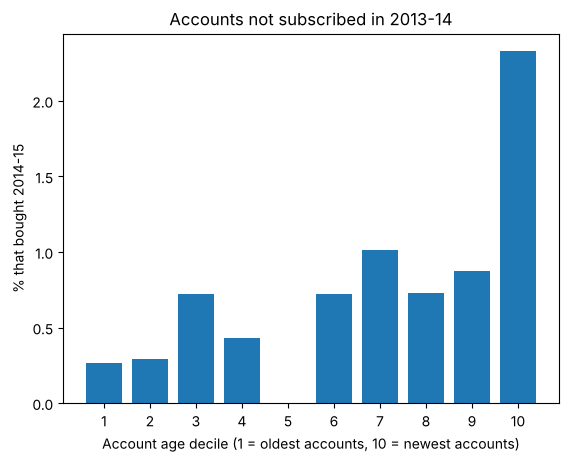

id_decile
1     0.26
2     0.29
3     0.72
4     0.43
5     0.00
6     0.72
7     1.01
8     0.73
9     0.87
10    2.33


In [31]:
# First we split the training accounts in 10 groups of the same size by account age
tr['id_decile'] = pd.qcut(X_id['id_rank'].values, 10, labels=False) + 1

# Then we calculate the proportion of buyers in each group, only for the accounts not subscribed in 2013-14
not_sub_2013 = tr[~tr['subscribed_2013']]
rate_by_decile = not_sub_2013.groupby('id_decile')['label'].mean()

# Finally we plot it
plt.bar(rate_by_decile.index, 100 * rate_by_decile.values)
plt.xlabel('Account age decile (1 = oldest accounts, 10 = newest accounts)')
plt.ylabel('% that bought 2014-15')
plt.title('Accounts not subscribed in 2013-14')
plt.xticks(range(1, 11))
plt.show()

print((100 * rate_by_decile).round(2).to_string())

As we can see, the newest accounts buy much more often than the oldest ones (around 7 times more in the last group). This makes sense: a new account is usually a patron who just discovered the orchestra (for example after buying a ticket), while a very old account without a recent subscription is probably someone who stopped coming.

Now we check if the feature improves the logistic regression, using the same CV splits as before, so we can compare both models fold by fold.

In [32]:
lr_model = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000))

# We evaluate the same model with and without the new feature
aucs_base = cv_auroc(lr_model, X, y)
aucs_id = cv_auroc(lr_model, X_id, y)

print('LR, 37 features:           {:.4f} +/- {:.4f}'.format(aucs_base.mean(), aucs_base.std()))
print('LR, 37 features + id_rank: {:.4f} +/- {:.4f}'.format(aucs_id.mean(), aucs_id.std()))

# Since both use the same folds, we can count in how many folds the new feature helps
print('Mean difference: {:+.4f}, better in {}/15 folds'.format((aucs_id - aucs_base).mean(), np.sum(aucs_id > aucs_base)))

LR, 37 features:           0.9773 +/- 0.0073
LR, 37 features + id_rank: 0.9840 +/- 0.0058
Mean difference: +0.0067, better in 15/15 folds


Adding only this feature increases the CV AUROC from 0.977 to 0.984, and the model is better in **all 15 folds**. This is much bigger than any improvement we got from tuning the models, and it is consistent, so it is not noise.

With this feature it makes sense to try the ensembles again. The effect of the account age is not linear: among the 2013-14 subscribers the old accounts are the loyal ones (more likely to renew), while among the rest the new accounts are the most likely to buy. A random forest can capture this, so this time it may help the logistic regression.

In [33]:
base_id = {
    'LR': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
    'RF': RandomForestClassifier(n_estimators=800, min_samples_leaf=10, max_features='sqrt', n_jobs=-1, random_state=0),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=800)),
    'AdaBoost': AdaBoostClassifier(n_estimators=ada_n, learning_rate=ada_lr, random_state=0),
    'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=mlp_layers, alpha=mlp_alpha, max_iter=1000, random_state=0)),
}

# Weight of each model in the average
combinations = {'LR': {'LR': 1}, 'LR + KNN': {'LR': 0.5, 'KNN': 0.5}, 'LR + MLP (70/30)': {'LR': 0.7, 'MLP': 0.3},
                'LR + AdaBoost (70/30)': {'LR': 0.7, 'AdaBoost': 0.3}, 'LR + RF (50/50)': {'LR': 0.5, 'RF': 0.5},
                'LR + RF (70/30)': {'LR': 0.7, 'RF': 0.3}}
ens_aucs_id = {name: [] for name in combinations}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
for train_index, val_index in cv.split(X_id, y):

    # First we fit each model on the training folds and get its probabilities for the validation fold
    probs = {}
    for name, model in base_id.items():
        model.fit(X_id.iloc[train_index], y[train_index])
        probs[name] = model.predict_proba(X_id.iloc[val_index])[:, 1]

    # Then we calculate the weighted average of each combination and its AUROC
    for name, weights in combinations.items():
        avg_probs = sum(w * probs[m] for m, w in weights.items())
        ens_aucs_id[name].append(roc_auc_score(y[val_index], avg_probs))

# Finally we compare each combination with the logistic regression with id_rank, and with the first model
lr_id_aucs = np.array(ens_aucs_id['LR'])
ensemble_table_id = []
for name, aucs in ens_aucs_id.items():
    aucs = np.array(aucs)
    ensemble_table_id.append({'model': name, 'CV AUROC': aucs.mean(), 'std': aucs.std(),
                              'diff vs LR + id_rank': (aucs - lr_id_aucs).mean(),
                              'folds better than LR + id_rank': '{}/15'.format(np.sum(aucs > lr_id_aucs)),
                              'folds better than first model': '{}/15'.format(np.sum(aucs > aucs_base))})

pd.DataFrame(ensemble_table_id).round(4)

,model,CV AUROC,std,diff vs LR + id_rank,folds better than LR + id_rank,folds better than first model
0,LR,0.9840,0.0058,0.0000,0/15,15/15
1,LR + KNN,0.9849,0.0061,0.0008,6/15,15/15
2,LR + MLP (70/30),0.9847,0.0054,0.0006,9/15,15/15
3,LR + AdaBoost (70/30),0.9855,0.0059,0.0015,12/15,15/15
4,LR + RF (50/50),0.9862,0.0052,0.0022,11/15,14/15
5,LR + RF (70/30),0.9865,0.0051,0.0024,12/15,15/15


Now the ensemble with the random forest does help. Giving 70% of the weight to the logistic regression and 30% to the random forest is the best combination (CV AUROC ≈ 0.986). It beats the logistic regression with `id_rank` in 12 of the 15 folds and the first model in all of them. The 50/50 average is a bit worse, because the logistic regression is still the stronger model and should have more weight. AdaBoost also helps a bit (0.9855), but less than the random forest, and KNN and the MLP add very little (0.9849 and 0.9847).

**A note on leakage.** The account age does not describe the patron, it comes from how the orchestra's database creates the IDs. The IDs exist before the 2014-15 season, so the feature does not use future information, and we compute it in the same way for train and test. Still, part of the signal could come from how the dataset was built. In a real project I would check with the orchestra that the account creation date is known before the season starts. For this competition I kept it, because it only uses the data we were given and it improves every fold.

## 13. Final model and submission

The final model is the weighted average of the logistic regression (70%) and the random forest (30%), both trained on the 37 features plus `id_rank`, using all the training data.

In [34]:
# First we train both models on all the training data
final_lr = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)).fit(X_id, y)
final_rf = RandomForestClassifier(n_estimators=800, min_samples_leaf=10, max_features='sqrt', n_jobs=-1, random_state=0).fit(X_id, y)

# Then we average their probabilities with the weights we chose with the CV
test_probs_final = 0.7 * final_lr.predict_proba(X_test_id)[:, 1] + 0.3 * final_rf.predict_proba(X_test_id)[:, 1]

# We create the submission file and check the format again
submission_final = pd.DataFrame({'ID': test['ID'], 'Predicted': test_probs_final})
assert list(submission_final.columns) == list(sample_submission.columns)
assert (submission_final['ID'].values == sample_submission['ID'].values).all()
assert submission_final['Predicted'].between(0, 1).all()

# Finally we save it and compare it with the first submission
submission_final.to_csv(SUBMISSIONS_PATH + 'final_ensemble.csv', index=False)
print(submission_final.shape)
print('Mean predicted probability: {:.4f} (positive rate in train: {:.4f})'.format(test_probs_final.mean(), y.mean()))
print('Correlation with the first submission: {:.3f}'.format(np.corrcoef(test_probs, test_probs_final)[0, 1]))

(2975, 2)
Mean predicted probability: 0.0488 (positive rate in train: 0.0478)
Correlation with the first submission: 0.995


The average predicted probability is very close to the 4.8% of buyers in train, and the predictions are very similar to the first submission (correlation 0.995).

## 14. Conclusion

- The most important part was the **feature engineering**, especially the subscription history: loyalty (streak, number of seasons) and recency (years since the last subscription) explain most of the target. Donations, tickets and location add smaller but consistent improvements.
- I validated every decision with **repeated stratified 5-fold CV** and compared models fold by fold on the same splits. This gave stable results with only 332 buyers, and I never chose a model using the public leaderboard.
- A simple rule based on loyalty already reaches 0.935, and the models from class go clearly beyond it. After tuning all of them (logistic regression, random forest, KNN, SVC, boosting and a small neural network), I chose the **logistic regression**: it was tied with the MLP at the top but it is simpler and easier to explain (CV AUROC ≈ 0.977, public score 0.97228). Averaging it with other models did not help in a consistent way.
- The biggest improvement came from one extra feature, the **account age** taken from the IDs (CV AUROC from 0.977 to 0.984, better in 15/15 folds). With this feature the random forest became useful, and the final model (70% logistic regression + 30% random forest) reached a CV AUROC of ≈ 0.986.
- In the end, a better feature helped much more than a better model: the top six tuned models were within 0.005 AUROC of each other.